# 07 - Despacho dinâmico

O notebook 06 mostrou que **janelas fixas** não funcionam: o pedido espera o lote fechar e perde o prazo. Aqui testamos a alternativa: **decidir pedido a pedido**.

**Regra (por hub, no Centro de cada cidade):**
- Pedido chega e há uma moto "aberta": ele entra se ainda existir uma ordem de visita em que **todos** cumprem o prazo (menos uma margem de segurança).
- A moto sai quando lota (4 pedidos), quando atinge a **espera máxima**, ou no último minuto que ainda cumpre o prazo de todos - o que vier primeiro.
- Rota: com até 4 paradas testamos todas as ordens possíveis (24) e ficamos com a de menor km que cumpre o prazo.

**Duas medidas de prazo:**
- **Planejado:** tempo médio de viagem (como o sistema enxerga na hora de decidir).
- **Com variação:** cada viagem recebe um fator aleatório de tempo (trânsito do momento). É o que aconteceria na rua - e é aqui que a espera cobra seu preço.

**Cenários:** espera máxima de 0, 2, 5, 10 e 15 min; margem de 0 ou 5 min; volume atual e 4x. Toda a operação entra (não só lotes), e cada cenário é comparado com as viagens individuais do mesmo volume. Código em `src/logistica_rotas/roteirizacao/despacho.py`.

## 1. Configuração e simulação

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "src"))

from logistica_rotas.ingestao.leitura import carregar_entregas
from logistica_rotas.limpeza.tratamento import CAMINHO_PROCESSED, limpar_entregas, salvar_parquet

pd.set_option("display.float_format", "{:.1f}".format)
pd.set_option("display.width", 140)

if not CAMINHO_PROCESSED.exists():  # Parquet fica fora do Git: gera a partir do CSV se faltar
    salvar_parquet(limpar_entregas(carregar_entregas()), CAMINHO_PROCESSED)
df = pd.read_parquet(CAMINHO_PROCESSED)

from logistica_rotas.roteirizacao.despacho import resumo_despacho, rodar_cenarios, simular_despacho
from logistica_rotas.visualizacao import graficos as g

cenarios = rodar_cenarios(df)  # cerca de 1 minuto
colunas = ["volume", "politica", "margem_min", "espera_max_min", "entregas_por_viagem", "economia_km_pct",
           "espera_media_min", "no_prazo_plan_pct", "no_prazo_real_pct"]
cenarios[colunas]

,volume,politica,margem_min,espera_max_min,entregas_por_viagem,economia_km_pct,espera_media_min,no_prazo_plan_pct,no_prazo_real_pct
0,atual (5.000 pedidos),individual,0.0,0.0,1.0,0.0,0.0,98.4,97.0
1,atual (5.000 pedidos),dinâmico,0.0,0.0,1.0,0.2,0.0,98.4,97.1
2,atual (5.000 pedidos),dinâmico,0.0,2.0,1.0,1.2,1.9,98.4,95.9
3,atual (5.000 pedidos),dinâmico,0.0,5.0,1.1,2.7,4.6,98.4,93.7
4,atual (5.000 pedidos),dinâmico,0.0,10.0,1.2,4.2,8.4,98.4,86.3
5,atual (5.000 pedidos),dinâmico,0.0,15.0,1.2,5.2,11.1,98.4,73.5
6,atual (5.000 pedidos),dinâmico,5.0,0.0,1.0,0.2,0.0,98.4,96.7
7,atual (5.000 pedidos),dinâmico,5.0,2.0,1.0,1.0,1.8,98.4,96.4
8,atual (5.000 pedidos),dinâmico,5.0,5.0,1.1,2.0,4.3,98.4,95.3
9,atual (5.000 pedidos),dinâmico,5.0,10.0,1.1,2.9,7.4,98.4,94.1


## 2. Curva de troca: km x prazo na rua

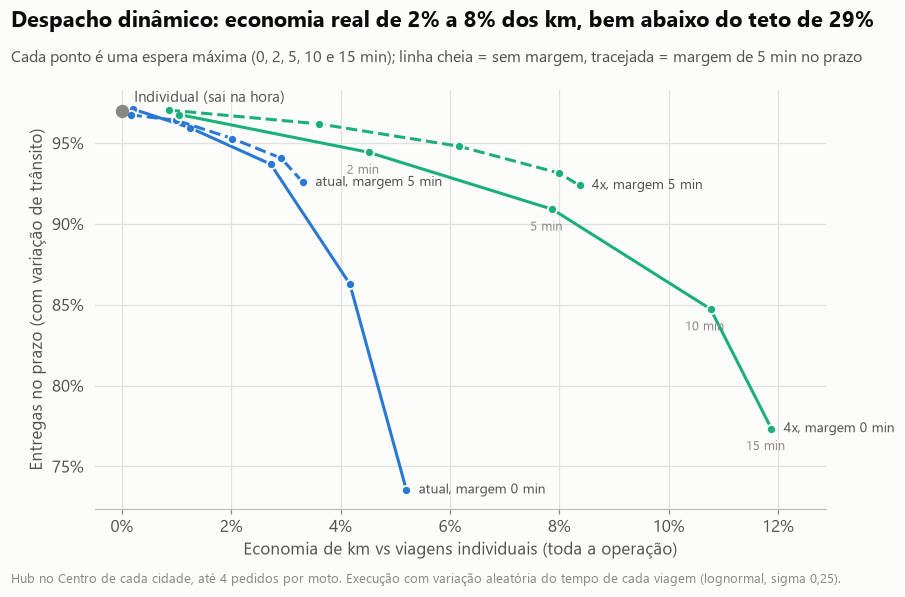

In [2]:
fig = g.curva_despacho_dinamico(cenarios, 'Despacho dinâmico: economia real de 2% a 8% dos km, bem abaixo do teto de 29%')
g.salvar_figura(fig, "13_despacho_dinamico");

**Leitura:**
- **No planejamento, o prazo fica intacto.** Em todos os cenários, as entregas planejadas no prazo ficam iguais às das viagens individuais (98,4% no volume atual), porque a regra só espera enquanto o prazo permite.
- **Na rua, a espera cobra seu preço.** Esperar consome a folga que protegia contra o trânsito. Sem margem, esperar até 15 minutos derruba as entregas no prazo para 73,5% (volume atual), contra 97,0% saindo na hora.
- **A margem de 5 minutos segura o prazo.** Com ela, esperar até 5 minutos dá 95,3% no prazo (atual) e 94,8% (4x), perdendo cerca de 2 pontos.
- **A economia depende do volume.** No volume atual, com margem de 5 min e espera de 5 min, a economia é de só 2,0%: os pedidos de uma cidade raramente chegam com poucos minutos de diferença. Com 4 vezes o volume, a mesma regra economiza 6,2%, e 8,0% com espera de até 10 minutos (93,1% no prazo).
- **Comparação com a janela fixa** (notebook 06, prazo planejado): a janela de 15 minutos dava 84% no prazo. No despacho dinâmico, o prazo planejado não cai.

## 3. Onde o ganho aparece

Cenário com margem de 5 min e espera máxima de 5 min, volume atual: economia e prazo por cidade e por horário.

In [3]:
individual = simular_despacho(df, 0, capacidade=1)
dinamico = simular_despacho(df, 5, capacidade=4, margem_min=5)

def por_grupo(entregas, chave):
    return entregas.groupby(chave).apply(lambda e: resumo_despacho(e), include_groups=False)

ind_c, din_c = por_grupo(individual, "cidade_hub"), por_grupo(dinamico, "cidade_hub")
pd.DataFrame({
    "pedidos": ind_c["entregas"].astype(int),
    "economia_km_pct": (1 - din_c["km"] / ind_c["km"]) * 100,
    "entregas_por_viagem": din_c["entregas_por_viagem"],
    "no_prazo_real_individual": ind_c["no_prazo_real_pct"],
    "no_prazo_real_dinamico": din_c["no_prazo_real_pct"],
}).sort_values("pedidos", ascending=False)

,pedidos,economia_km_pct,entregas_por_viagem,no_prazo_real_individual,no_prazo_real_dinamico
cidade_hub,,,,,
São Bernardo do Campo,1410,2.4,1.1,95.7,93.2
Santo André,1290,2.4,1.1,98.2,96.7
Diadema,792,2.0,1.1,96.3,94.8
Mauá,753,1.2,1.1,98.0,96.9
São Caetano do Sul,545,1.6,1.0,96.9,95.8


In [4]:
ind_p, din_p = por_grupo(individual, "pico"), por_grupo(dinamico, "pico")
pd.DataFrame({
    "economia_km_pct": (1 - din_p["km"] / ind_p["km"]) * 100,
    "entregas_por_viagem": din_p["entregas_por_viagem"],
    "no_prazo_real_individual": ind_p["no_prazo_real_pct"],
    "no_prazo_real_dinamico": din_p["no_prazo_real_pct"],
}).rename(index={False: "fora do pico", True: "pico"})

,economia_km_pct,entregas_por_viagem,no_prazo_real_individual,no_prazo_real_dinamico
pico,,,,
fora do pico,2.3,1.1,98.6,97.5
pico,0.7,1.0,90.3,86.5


**Leitura:**
- **Por cidade:** a economia é pequena em todas (de 1,2% a 2,4%). As maiores ficam em São Bernardo e Santo André, que têm mais pedidos e, portanto, mais chances de combinar dois deles.
- **Por horário:** no pico, o despacho dinâmico quase não economiza (0,7%) e é onde mais perde prazo (de 90,3% para 86,5%). Com menos folga, sobram poucas combinações, e a espera pesa mais. Fora do pico, a economia é de 2,3%, com perda de 1,1 ponto.
- **Regra prática:** não esperar no pico. Esperar só fora dele.

## 4. Conclusões

1. **A estimativa realista é muito menor que o teto.** Os 29% do notebook 05 supunham pedidos já disponíveis. Com pedidos chegando ao longo do tempo, o despacho dinâmico economiza de 1% a 3% no volume atual e de 4% a 8% com 4 vezes o volume.
2. **Perde-se de 1 a 5 pontos de prazo.** A margem de segurança de 5 minutos é obrigatória: sem ela, esperas de 10 a 15 minutos derrubam o prazo para 73% a 86%.
3. **Política sugerida (hipótese a testar):** margem de 5 minutos, espera máxima de 5 minutos fora do pico e nenhuma espera no pico.
4. **Quando vale a pena:** com mais volume por hub, como em horários de pico de demanda (almoço e jantar), em cidades maiores ou com vários restaurantes num mesmo ponto de coleta.

**Limitações:**
- O hub único por cidade é uma simplificação: na realidade, cada restaurante é um ponto de coleta, e isso reduz as combinações possíveis.
- A variação do tempo é a mesma para todas as paradas de uma viagem.
- A distância é em linha reta multiplicada por 1,3.
- Não simulamos frota limitada: sempre há moto disponível.

**Próximos passos possíveis:**
1. Testar a política "sem espera no pico" diretamente.
2. Usar coletas em vários pontos, e não só no hub.
3. Usar distância e tempo reais pela malha viária (OSRM, que exige serviço externo).